# Icon Array (Risk Communication)

**Family:** Uncertainty &nbsp;|&nbsp; **Library:** matplotlib / seaborn

> *Uncertainty:* Show what is not known (intervals, probabilities and possible outcomes) so readers do not over-trust a single number.

## Design purpose

Shows a probability as a grid of 100 people, colouring those affected. Natural frequencies ("7 in 100") shown as countable figures are understood far better than percentages or relative risks, especially by people with low numeracy. Icon arrays are a recommended format in patient decision aids.

## When to use

- Communicate a risk or benefit to patients or the public
- Compare absolute risks between options (treatment vs no treatment)
- Counter the inflation produced by relative risk ("doubles the risk" from 1 to 2 in 100)

## Avoid when

- The risk is very small (under 1 in 1,000 needs 1,000 icons; use a different denominator or text)
- The audience is technical and needs intervals or many comparisons

## Alternatives

- Waffle chart (same idea, abstract squares)
- Quantile dotplot (for distributions)
- A plain sentence with natural frequencies

## Design tips

- Use the same denominator (100) for every option you compare
- Group the affected icons together, starting from one corner
- State the number in words next to each array

## Example

The chance of a serious side effect within one year: 7 in 100 patients on Treatment A and 15 in 100 on Treatment B (illustrative numbers).

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

from matplotlib.patches import Circle, FancyBboxPatch

### Data

In [2]:
options = pd.DataFrame({"option": ["Treatment A", "Treatment B"], "affected_per_100": [7, 15]})
options

,option,affected_per_100
0,Treatment A,7
1,Treatment B,15


### Plot

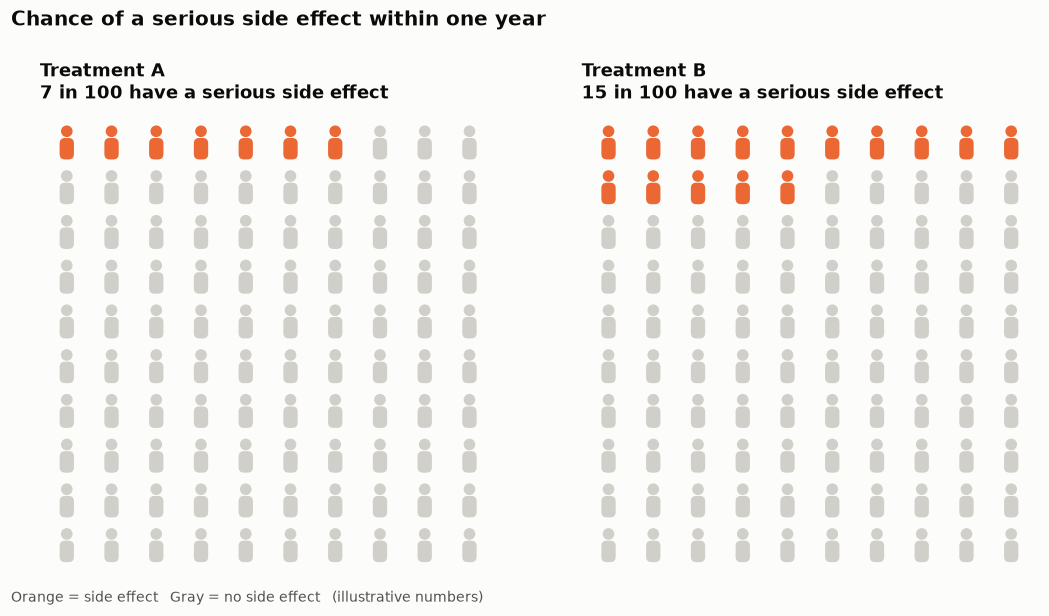

In [3]:
def person(ax, x, y, color):
    ax.add_patch(Circle((x, y + 0.27), 0.13, color=color, linewidth=0))
    ax.add_patch(FancyBboxPatch((x - 0.16, y - 0.36), 0.32, 0.48,
                                boxstyle="round,pad=0,rounding_size=0.12", color=color, linewidth=0))

fig, axes = plt.subplots(1, 2, figsize=(10, 5.6))
for ax, row in zip(axes, options.itertuples()):
    for k in range(100):
        r, c = divmod(k, 10)
        person(ax, c, 9 - r, PALETTE[1] if k < row.affected_per_100 else "#d0cfca")
    ax.set_xlim(-0.6, 9.6)
    ax.set_ylim(-0.6, 9.8)
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title(f"{row.option}\n{row.affected_per_100} in 100 have a serious side effect",
                 loc="left", fontsize=12)
fig.suptitle("Chance of a serious side effect within one year", x=0.02, ha="left",
             fontsize=13, fontweight="bold")
fig.text(0.02, 0.02, "Orange = side effect   Gray = no side effect   (illustrative numbers)",
         fontsize=9, color="#52514e")
fig.tight_layout(rect=(0, 0.04, 1, 0.92))
plt.show()

## How to read it

Each figure is one patient out of 100. Count the orange figures: 7 on Treatment A and 15 on Treatment B. B roughly doubles the risk, but most patients on either treatment have no serious side effect.

---
Standalone script: [`icon_array.py`](icon_array.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)